In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

In [2]:
dataset_path = Path("../dataset/raw")

print(dataset_path.exists())

True


In [3]:
print(list(dataset_path.iterdir()))


[WindowsPath('../dataset/raw/Tomato_Bacterial_spot'), WindowsPath('../dataset/raw/Tomato_Early_blight'), WindowsPath('../dataset/raw/Tomato_healthy'), WindowsPath('../dataset/raw/Tomato_Late_blight'), WindowsPath('../dataset/raw/Tomato_Leaf_Mold'), WindowsPath('../dataset/raw/Tomato_Septoria_leaf_spot'), WindowsPath('../dataset/raw/Tomato_Spider_mites_Two_spotted_spider_mite'), WindowsPath('../dataset/raw/Tomato__Target_Spot'), WindowsPath('../dataset/raw/Tomato__Tomato_mosaic_virus'), WindowsPath('../dataset/raw/Tomato__Tomato_YellowLeaf__Curl_Virus')]


In [4]:
classes = [
    folder.name
    for folder in dataset_path.iterdir()
    if folder.is_dir()
    and folder.name.startswith("Tomato")
]

print(classes)

['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [5]:
print("Total Classes:", len(classes))

Total Classes: 10


In [6]:
folder_path = dataset_path / classes[0]

images = list(folder_path.glob("*"))

print("Total Images:", len(images))

Total Images: 2127


In [7]:
data = []

for class_name in classes:

    folder_path = dataset_path / class_name

    images = list(folder_path.glob("*"))

    data.append({
        "Class": class_name,
        "Image_Count": len(images)
    })

df = pd.DataFrame(data)

print(df)

                                         Class  Image_Count
0                        Tomato_Bacterial_spot         2127
1                          Tomato_Early_blight         1000
2                               Tomato_healthy         1591
3                           Tomato_Late_blight         1909
4                             Tomato_Leaf_Mold          952
5                    Tomato_Septoria_leaf_spot         1771
6  Tomato_Spider_mites_Two_spotted_spider_mite         1676
7                          Tomato__Target_Spot         1404
8                  Tomato__Tomato_mosaic_virus          373
9        Tomato__Tomato_YellowLeaf__Curl_Virus         3209


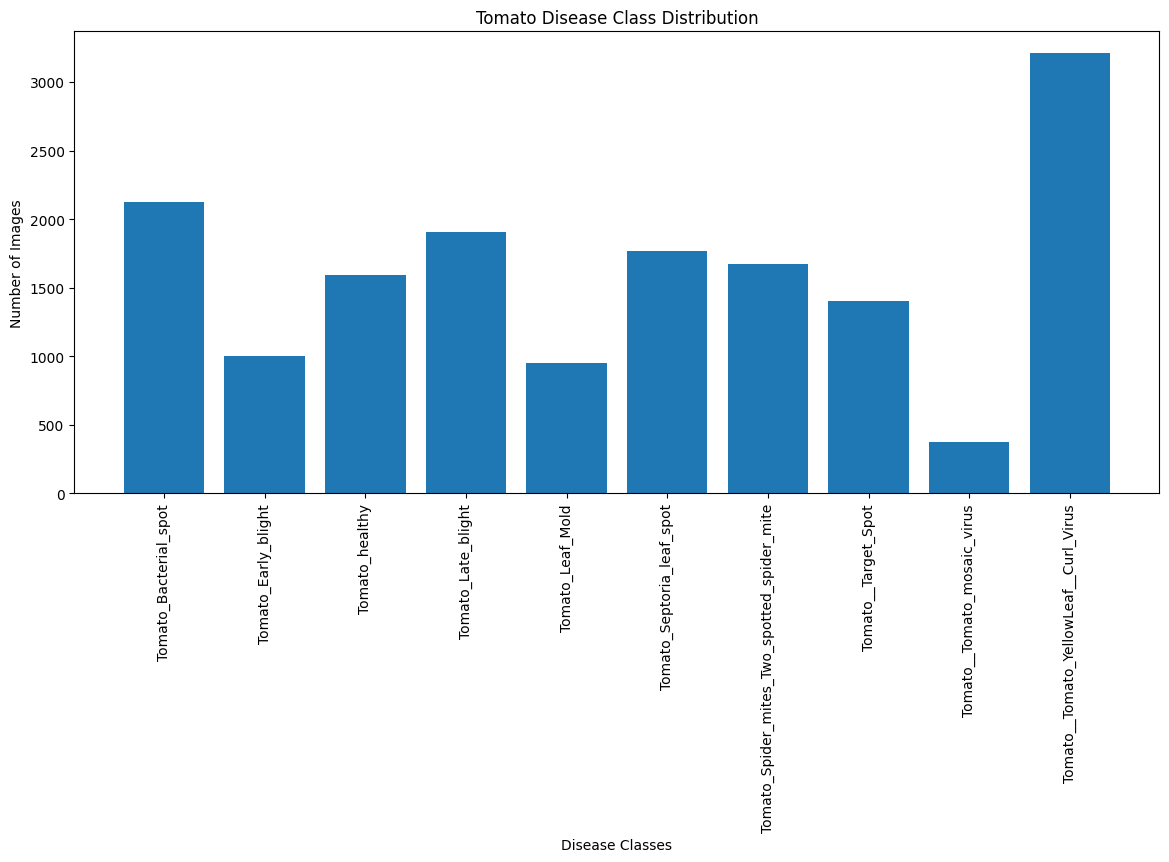

In [10]:
plt.figure (figsize=(14,6))
plt.bar(
    df['Class'],
    df['Image_Count']
)

plt.xticks(rotation=90)

plt.xlabel("Disease Classes")

plt.ylabel("Number of Images")

plt.title("Tomato Disease Class Distribution")

plt.show()

In [11]:
total_images = df["Image_Count"].sum()

print("Total Images:", total_images)

Total Images: 16012


In [12]:
print(df["Image_Count"].describe())

count      10.000000
mean     1601.200000
std       768.911467
min       373.000000
25%      1101.000000
50%      1633.500000
75%      1874.500000
max      3209.000000
Name: Image_Count, dtype: float64


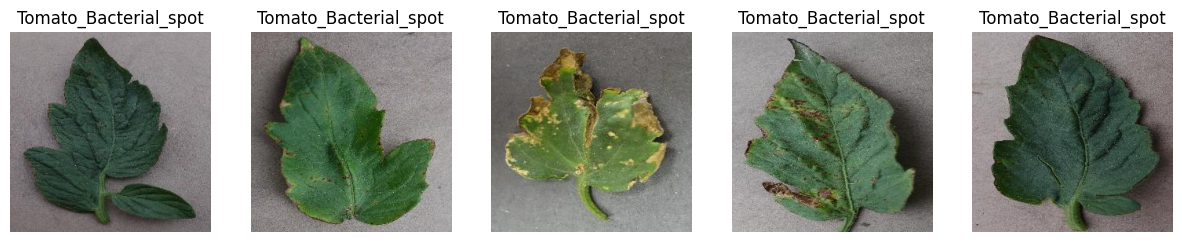

In [14]:
class_name = classes[0]

folder_path = dataset_path / class_name

images = list(folder_path.glob("*"))

plt.figure(figsize=(15, 5))

for i in range(5):

    img = Image.open(images[i]).convert("RGB")

    plt.subplot(1, 5, i + 1)

    plt.imshow(img)

    plt.title(class_name)

    plt.axis("off")

plt.show()

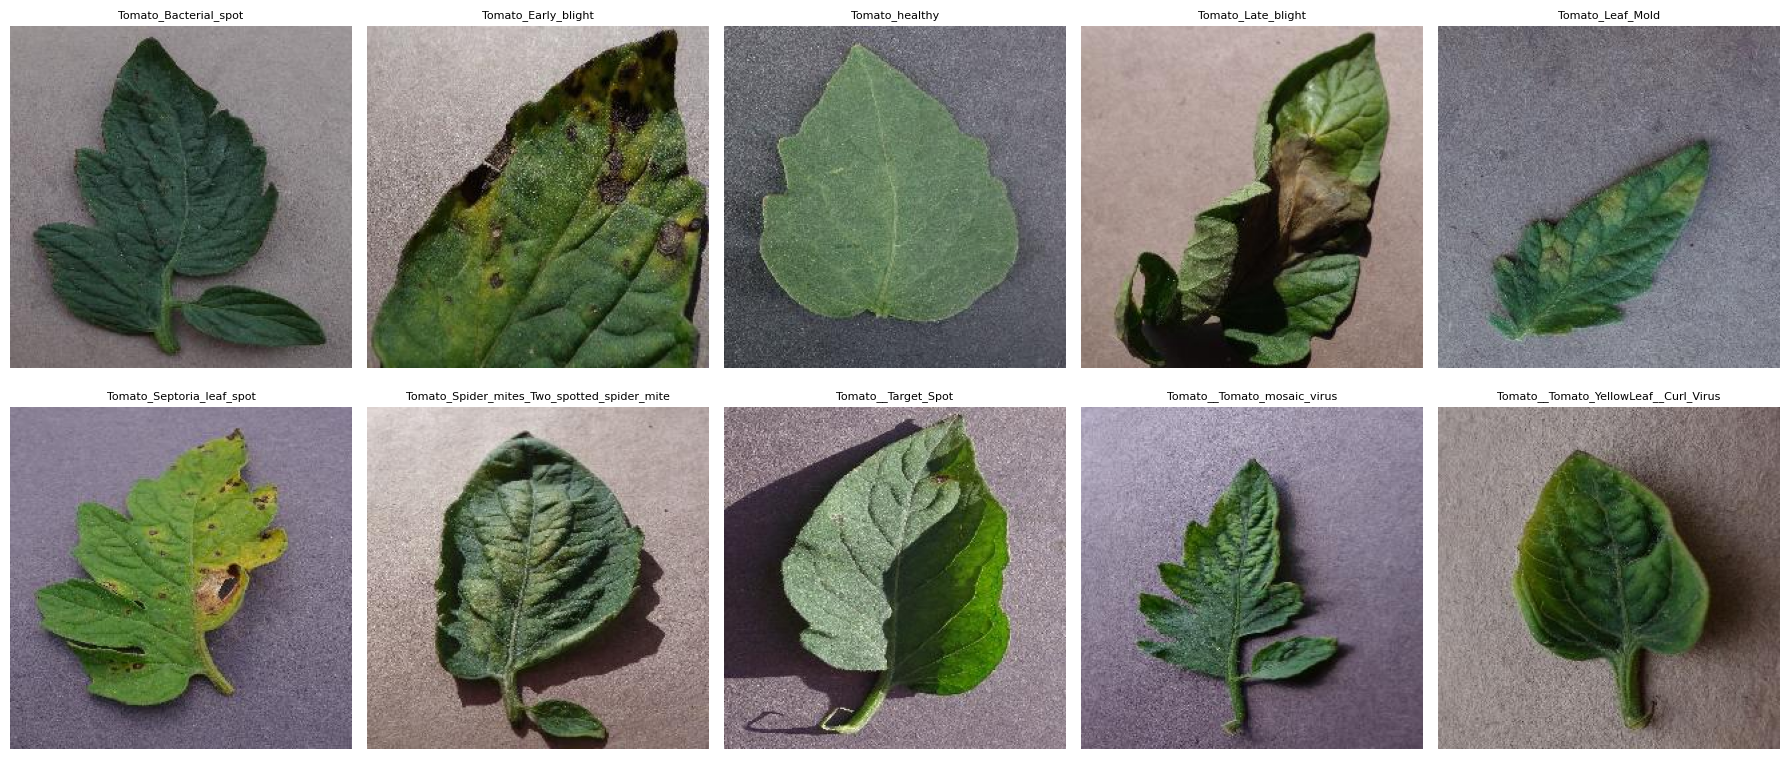

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for i, class_name in enumerate(classes[:10]):

    folder_path = dataset_path / class_name

    images = list(folder_path.glob("*"))

    img = Image.open(images[0]).convert("RGB")

    row = i // 5
    col = i % 5

    axes[row, col].imshow(img)

    axes[row, col].set_title(class_name, fontsize=8)

    axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [16]:
img = Image.open(images[0]).convert("RGB")

print("Width:", img.width)
print("Height:", img.height)
print("Mode:", img.mode)

Width: 256
Height: 256
Mode: RGB


In [17]:
img_array = np.array(img)

print("Image Shape:", img_array.shape)

Image Shape: (256, 256, 3)


In [20]:
valid_extensions = [".jpg", ".jpeg", ".png"]

def get_images(folder_path):

    images = []

    for file in folder_path.iterdir():

        if file.is_file() and file.suffix.lower() in valid_extensions:
            images.append(file)

    return images

In [22]:
image_sizes = []

for class_name in classes:

    folder_path = dataset_path / class_name

    images = get_images(folder_path)

    for image_path in images:

        try:
            with Image.open(image_path) as img:

                image_sizes.append({
                    "Class": class_name,
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode
                })

        except Exception as e:
            print("Skipped:", image_path, e)

image_df = pd.DataFrame(image_sizes)

print(image_df.head())

                   Class  Width  Height Mode
0  Tomato_Bacterial_spot    256     256  RGB
1  Tomato_Bacterial_spot    256     256  RGB
2  Tomato_Bacterial_spot    256     256  RGB
3  Tomato_Bacterial_spot    256     256  RGB
4  Tomato_Bacterial_spot    256     256  RGB


In [23]:
corrupted_images = []

for class_name in classes:

    folder_path = dataset_path / class_name

    for image_path in folder_path.iterdir():

        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:

            try:
                with Image.open(image_path) as img:
                    img.verify()

            except Exception:
                corrupted_images.append(str(image_path))

print("Corrupted Images:", len(corrupted_images))

Corrupted Images: 0
